# Z3-Python 19 — La machine de Gödel : se réécrire seulement sur preuve

**Navigation** : [Index Z3-Python](README.md) | [Index SMT](../README.md) | [Index SymbolicAI](../../README.md) | [← 05 Quantificateurs et preuves](Z3-05-Quantifiers-Proofs-Python.ipynb)

## Objectifs d'apprentissage

À la fin de ce notebook, vous saurez :

1. Énoncer le **théorème cible** de la machine de Gödel (Schmidhuber 2006, équation (2)) et le prouver avec Z3 par réfutation : on montre que la négation est insatisfiable sous les axiomes de l'environnement.
2. Expliquer pourquoi la réécriture acceptée est **globalement** optimale (théorème 4.1) : l'utilité de « ne pas se réécrire » inclut tout ce que la recherche de preuve trouverait ensuite. Vous le verrez sur une machine qui refuse une amélioration réelle pour en attendre une meilleure.
3. Mesurer ce que coûte la prudence : une réécriture **empiriquement** meilleure mais non prouvable est refusée. Z3 fournit le contre-exemple qui justifie le refus, et un axiome supplémentaire sur l'environnement permet de récupérer le gain.
4. Compter le temps de preuve **dans** l'utilité : un budget de preuve trop petit ne prouve rien, un budget trop grand arrive trop tard.

## La source

Jürgen Schmidhuber, *Gödel Machines: Self-Referential Universal Problem Solvers Making Provably Optimal Self-Improvements*, rapport technique IDSIA-19-03, version 5, décembre 2006 ([arXiv:cs/0309048](https://arxiv.org/abs/cs/0309048)).

Ce notebook en reprend cinq éléments, avec la section du papier :

| Élément | Section | Ce que le notebook en fait |
|---|---|---|
| Utilité « valeur à venir » $u(s, Env) = E_\mu[\sum_{\tau=time}^{T} r(\tau) \mid s, Env]$ | 2.1, éq. (1) | récompense cumulée jusqu'à la fin de vie $T$ |
| Théorème cible : $u[s(t_1) \oplus (switchbit=1)] > u[s(t_1) \oplus (switchbit=0)]$ | 3.2, éq. (2) | une formule Z3, prouvée par réfutation |
| Optimalité globale : « continuer » contient toutes les réécritures futures | 4, théorème 4.1 | la machine compare au plan de sa propre recherche future, pas au statu quo |
| Le levier : interrompre une phase de calibrage coûteuse pour presser le levier | 4.4 | la politique initiale $e(1)$ et le premier candidat |
| Limites : une amélioration vraie mais non prouvable sous les axiomes $\mathcal{A}$ est ignorée | 2.4 | contre-exemple Z3 et prix de la prudence |

## Ce que le jouet garde et ce qu'il simplifie

La machine du papier peut réécrire **tout** son code, chercheur de preuves compris, et son chercheur énumère des *techniques de preuve* par recherche universelle (BIOPS, section 5). Le jouet garde la structure de décision et réduit le reste :

- les **réécritures candidates** sont une liste finie de politiques, énumérées dans un ordre fixe ; une réécriture remplace la politique et arrête la recherche (cas 7 de la section 6.1, où la machine efface son chercheur) ;
- le **chercheur de preuves** est Z3. Chaque tentative coûte un nombre fixe de pas de vie, posé comme un axiome du matériel (section 3.2, item 1a) ;
- l'**environnement** n'est pas connu, mais il appartient à une famille $\mathcal{M}$ décrite par des axiomes (item 1c). Prouver $u_{switch} > u_{keep}$ **pour tout** environnement de $\mathcal{M}$ entraîne l'inégalité des espérances de l'éq. (1) pour toute loi $\mu$ portée par $\mathcal{M}$.

In [1]:
# Imports. Le package pip s'appelle 'z3-solver'.
import random

import matplotlib.pyplot as plt
import numpy as np
from z3 import (Context, If, Not, Real, RealVal, Solver, get_version_string,
                sat, simplify, unsat)

print(f"z3-solver {get_version_string()}")

z3-solver 5.1.0


## 1. Le monde du levier et ses axiomes

L'environnement est celui de la section 4.4, enrichi d'un second levier :

- le **levier A** rapporte $r$ par pas, dès la première pression ;
- le **levier B** rapporte $q$ par pas, mais seulement après $w$ pressions d'échauffement qui ne rapportent rien.

La machine ne connaît ni $r$, ni $q$, ni $w$. Elle connaît des **axiomes** qui bornent ces paramètres. Deux jeux d'axiomes servent tout le notebook :

| Jeu | $r$ | $q$ | $w$ | lien entre les leviers |
|---|---|---|---|---|
| `base` | $[1, 2]$ | $[1, 4]$ | $[0, 30]$ | aucun |
| `savoir` | $[1, 2]$ | $[1, 4]$ | $[0, 20]$ | $q \geq r + 1$ |

La politique initiale $e(1)$ est la politique « prudente » de la section 4.4 : elle commence par 50 pas de **calibrage** qui ne rapportent rien, puis presse le levier A. Le papier prend l'exemple d'AIXI(t,l), dont la phase de mise en route a un coût constant que la notation $O()$ efface mais que l'utilité (1) compte. Les réécritures candidates sont « presser A » et « presser B », dans cet ordre.

In [2]:
AXIOMES = {
    "base":   dict(r=(1, 2), q=(1, 4), w=(0, 30), ecart=None),
    "savoir": dict(r=(1, 2), q=(1, 4), w=(0, 20), ecart=1),
}
CALIBRAGE = 50          # pas de calibrage de la politique initiale e(1)


def environnement(ctx, jeu, **surcharges):
    # Variables r, q, w dans un contexte Z3 neuf, plus les axiomes du jeu choisi.
    a = dict(AXIOMES[jeu], **surcharges)
    r, q, w = Real("r", ctx), Real("q", ctx), Real("w", ctx)
    axiomes = [r >= a["r"][0], r <= a["r"][1], q >= a["q"][0], q <= a["q"][1],
               w >= a["w"][0], w <= a["w"][1]]
    if a["ecart"] is not None:
        axiomes.append(q >= r + a["ecart"])
    return dict(r=r, q=q, w=w), axiomes


def positif(x):
    # max(x, 0), en Python pour un nombre, en Z3 pour une expression symbolique.
    if isinstance(x, (int, float)):
        return max(x, 0)
    return If(x > 0, x, RealVal(0, x.ctx))


# Une politique : (duree D d'action, environnement E) -> recompense cumulee sur D pas.
POLITIQUES = {
    "calibrage": lambda D, E: E["r"] * positif(D - CALIBRAGE),
    "A": lambda D, E: E["r"] * D,
    "B": lambda D, E: E["q"] * positif(D - E["w"]),
}

for jeu, a in AXIOMES.items():
    lien = f"q >= r + {a['ecart']}" if a["ecart"] is not None else "aucun"
    print(f"{jeu:7s} r in {a['r']}  q in {a['q']}  w in {a['w']}  lien : {lien}")
print(f"politique initiale e(1) : {CALIBRAGE} pas de calibrage, puis levier A")

base    r in (1, 2)  q in (1, 4)  w in (0, 30)  lien : aucun
savoir  r in (1, 2)  q in (1, 4)  w in (0, 20)  lien : q >= r + 1
politique initiale e(1) : 50 pas de calibrage, puis levier A


## 2. Le prouveur : le théorème cible par réfutation

`check()` (section 3.2, item 5) n'accepte une réécriture que si le dernier théorème de la preuve a la forme (2). Avec Z3, on obtient ce théorème en montrant que sa **négation** est insatisfiable sous les axiomes. Il y a trois issues :

- `unsat` : aucun environnement de $\mathcal{M}$ ne contredit l'inégalité, le théorème est **prouvé** ;
- `sat` : Z3 exhibe un environnement admissible où la réécriture ne gagne pas, c'est un **contre-exemple** ;
- `unknown` : le budget de preuve est épuisé avant la conclusion. La machine ne peut pas se réécrire.

Chaque preuve tourne dans un `Context` Z3 neuf. Le compteur de ressources `rlimit count` de Z3 est cumulatif par contexte : un contexte neuf le remet à zéro, ce qui rend le coût de chaque preuve **déterministe** d'une exécution à l'autre. C'est ce compteur qui mesure le travail du chercheur.

Le premier test reprend l'exemple de la section 4.4 : à $t_1 = 5$, sur une vie $T = 200$, presser A tout de suite rapporte-t-il plus que finir le calibrage ?

In [3]:
def prouver(jeu, cible, budget=None, **surcharges):
    # Prouve cible(E) pour tout E admissible. Renvoie (verdict, contre_exemple, rlimit consomme).
    ctx = Context()
    E, axiomes = environnement(ctx, jeu, **surcharges)
    s = Solver(ctx=ctx)
    if budget:
        s.set("rlimit", budget)
    s.add(axiomes)
    s.add(Not(cible(E)))
    res = s.check()
    stats = s.statistics()
    consomme = dict((k, stats.get_key_value(k)) for k in stats.keys()).get("rlimit count", 0)
    if res == unsat:
        return "PROUVE", None, consomme
    if res == sat:
        m = s.model()
        return "REFUTE", {k: m.eval(E[k], model_completion=True).as_fraction() for k in "rqw"}, consomme
    return "INCONNU", None, consomme


T, t1 = 200, 5
verdict, cex, cout = prouver(
    "savoir", lambda E: POLITIQUES["A"](T - t1, E) > POLITIQUES["calibrage"](T - t1, E))
print(f"A > calibrage (T={T}, t1={t1}) : {verdict}, rlimit consomme {cout}")

verdict, cex, cout = prouver(
    "base", lambda E: POLITIQUES["B"](T - t1, E) > POLITIQUES["A"](T - t1, E))
print(f"B > A sous 'base'           : {verdict}, rlimit consomme {cout}")
print(f"   contre-exemple : r={cex['r']}, q={cex['q']}, w={cex['w']}")

A > calibrage (T=200, t1=5) : PROUVE, rlimit consomme 282
B > A sous 'base'           : REFUTE, rlimit consomme 698
   contre-exemple : r=2, q=2, w=0


### Lecture du résultat

- **Premier théorème : prouvé.** Sous les axiomes `savoir`, presser A dès $t_1 = 5$ rapporte plus que finir le calibrage, et cela dans **tous** les environnements admissibles. Z3 l'établit pour un `rlimit` de 282. C'est l'exemple de la section 4.4 : le levier interrompt la phase de mise en route.
- **Second théorème : réfuté.** Sous `base`, B ne bat pas A partout. Z3 exhibe l'environnement $r = 2$, $q = 2$, $w = 0$ : les deux leviers rapportent autant par pas, et B rapporte alors exactement autant que A. Le théorème cible exige une inégalité stricte, donc il est faux dans cet environnement.

Le contre-exemple est l'information utile : il dit **pourquoi** la preuve échoue. Il suffit ici que $q$ puisse égaler $r$, et c'est précisément ce que l'axiome $q \geq r + 1$ du jeu `savoir` interdit.

## 3. La machine : se réécrire seulement si « continuer » est prouvé moins bon

La machine essaie les candidats dans l'ordre. Chaque tentative dure `cout_preuve` pas, pendant lesquels rien n'est rapporté et le calibrage est suspendu (un seul processeur, partagé entre le chercheur et la politique, cas 1 de la section 6.1).

Le cœur du théorème 4.1 est le terme de droite de l'éq. (2). « Ne pas basculer » ne veut pas dire « garder la politique actuelle pour toujours ». Cela veut dire « laisser la machine continuer », donc chercher les candidats suivants et basculer plus tard si elle le prouve. La machine calcule ce plan futur avant de prouver. Le calcul est déterministe : chaque preuve quantifie sur tout $\mathcal{M}$, donc son issue ne dépend pas de l'environnement réel. Ce plan donne ensuite le terme $u_{keep}$.

Pour comparer, une machine **gloutonne** utilise le même prouveur mais prend pour $u_{keep}$ le statu quo (« garder la politique actuelle »). C'est l'auto-amélioration locale que le théorème 4.1 écarte.

In [4]:
def utilite_plan(plan, T, E, depuis=0):
    # Recompense de 'depuis' a T d'un plan [(t_debut, politique)]. 'preuve' ne rapporte rien.
    total, calibre = 0, 0
    for k, (t0, nom) in enumerate(plan):
        t_fin = plan[k + 1][0] if k + 1 < len(plan) else T
        if t_fin <= depuis:
            continue
        D = t_fin - max(t0, depuis)
        if nom == "preuve":
            continue
        if nom == "calibrage":
            total = total + E["r"] * positif(D - (CALIBRAGE - calibre))
            calibre += D
        else:
            total = total + POLITIQUES[nom](D, E)
    return total


def machine(candidats, jeu, T, cout_preuve, budget=None, glouton=False, **surcharges):
    # Machine de Goedel jouet. Renvoie (plan, journal des tentatives).
    def suite(t, i):
        if i == len(candidats) or t + cout_preuve >= T:
            return [(t, "calibrage")], []
        t1 = t + cout_preuve
        plan_continuer, _ = suite(t1, i + 1)          # ce que ferait la machine sans basculer
        nom = candidats[i]

        def cible(E):
            u_switch = POLITIQUES[nom](T - t1, E)
            if glouton:
                u_keep = POLITIQUES["calibrage"](T - t1, E)
            else:
                u_keep = utilite_plan(plan_continuer, T, E, depuis=t1)
            return u_switch > u_keep

        verdict, cex, cout = prouver(jeu, cible, budget, **surcharges)
        entree = dict(t=t, candidat=nom, verdict=verdict, rlimit=cout, contre_exemple=cex)
        if verdict == "PROUVE":
            return [(t, "preuve"), (t1, nom)], [entree]
        plan, journal = suite(t1, i + 1)
        return [(t, "preuve")] + plan, [entree] + journal

    return suite(0, 0)


def gain_reel(plan, T, env):
    # Recompense effective du plan dans un environnement concret.
    ctx = Context()
    E = {k: RealVal(v, ctx) for k, v in env.items()}
    return float(simplify(utilite_plan(plan, T, E)).as_fraction())


def politique_finale(plan):
    return plan[-1][1]


VRAI = dict(r=1.5, q=3, w=10)       # l'environnement reel, inconnu de la machine

for glouton in (False, True):
    plan, journal = machine(["A", "B"], "savoir", T=200, cout_preuve=5, glouton=glouton)
    nom = "gloutonne" if glouton else "de Goedel"
    print(f"--- machine {nom} ---")
    for e in journal:
        print(f"  t={e['t']:3d}  candidat {e['candidat']}  {e['verdict']:7s}  rlimit {e['rlimit']}")
    print(f"  plan : {plan}")
    print(f"  recompense dans l'environnement reel {VRAI} : {gain_reel(plan, 200, VRAI)}")

--- machine de Goedel ---
  t=  0  candidat A  REFUTE   rlimit 790
  t=  5  candidat B  PROUVE   rlimit 942
  plan : [(0, 'preuve'), (5, 'preuve'), (10, 'B')]
  recompense dans l'environnement reel {'r': 1.5, 'q': 3, 'w': 10} : 540.0
--- machine gloutonne ---
  t=  0  candidat A  PROUVE   rlimit 282
  plan : [(0, 'preuve'), (5, 'A')]
  recompense dans l'environnement reel {'r': 1.5, 'q': 3, 'w': 10} : 292.5


### Lecture du résultat

Les deux machines utilisent le même prouveur et les mêmes axiomes. Elles ne diffèrent que par le terme de droite du théorème cible.

- La machine **gloutonne** compare A au statu quo, c'est-à-dire au calibrage. Elle le prouve dès la première tentative et se réécrit à $t = 5$. Elle obtient 292,5 dans l'environnement réel.
- La machine **de Gödel** compare A à ce qu'elle ferait si elle continuait. Or elle prévoit qu'elle prouverait B au pas suivant. Le théorème « A bat ce plan » est donc **réfuté** : dans certains environnements admissibles, B fait mieux. La machine ne se réécrit pas en A, prouve B à $t = 5$, bascule à $t = 10$ et obtient 540.

C'est le théorème 4.1 en action. La machine a refusé une amélioration réelle et prouvable, celle de A sur le calibrage, parce qu'elle savait en trouver une meilleure en continuant à chercher. Elle a perdu 5 pas de plus en preuve, ce qui pèse peu face à l'écart final de 247,5.

## 4. Optimalité globale : balayer la durée de vie

L'avantage de la machine de Gödel sur la gloutonne devrait dépendre de la vie qui reste. B demande un échauffement, et cet échauffement ne se rentabilise que sur une vie assez longue. On fait varier $T$ de 15 à 200 avec le jeu `savoir`. Pour chaque $T$, on relève la politique adoptée par chaque machine et la récompense obtenue dans l'environnement réel.

On mesure aussi la différence Gödel moins glouton sur 2 000 environnements tirés uniformément dans $\mathcal{M}$ (graine fixe), pas seulement dans l'environnement réel : le théorème 4.1 porte sur tous les environnements admissibles, pas sur un seul.

 T  Goedel glouton  reel(G)  reel(gl)  min(G-gl) sur M  moy(G-gl)
 15  A      A           15.0      15.0              0.0        0.0
 20  A      A           22.5      22.5              0.0        0.0
 25  A      A           30.0      30.0              0.0        0.0
 30  A      A           37.5      37.5              0.0        0.0
 35  B      A           45.0      45.0            -41.7        5.5
 40  B      A           60.0      52.5            -34.5       14.4
 60  B      A          120.0      82.5            -11.8       50.0
100  B      A          240.0     142.5             30.9      121.0
150  B      A          390.0     217.5             83.6      209.9
200  B      A          540.0     292.5            134.8      298.7

Premier T ou les deux machines divergent : 35
T ou la gloutonne fait mieux dans au moins un environnement de M : [35, 40, 45, 50, 55, 60, 65, 70]


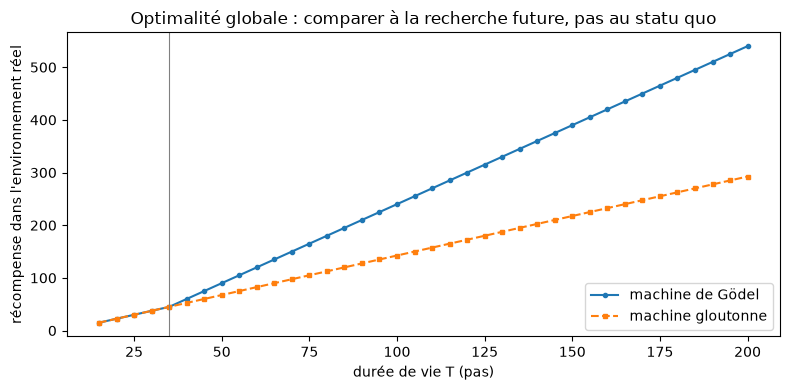

In [5]:
rng = random.Random(42)
a = AXIOMES["savoir"]
echantillon = []
while len(echantillon) < 2000:
    env = dict(r=rng.uniform(*a["r"]), q=rng.uniform(*a["q"]), w=rng.uniform(*a["w"]))
    if env["q"] >= env["r"] + a["ecart"]:          # rejet : on reste dans M
        echantillon.append(env)


def gain_numpy(plan, T, envs):
    # Version vectorisee de gain_reel sur un echantillon d'environnements.
    r = np.array([e["r"] for e in envs]); q = np.array([e["q"] for e in envs])
    w = np.array([e["w"] for e in envs])
    total, calibre = np.zeros(len(envs)), 0
    for k, (t0, nom) in enumerate(plan):
        t_fin = plan[k + 1][0] if k + 1 < len(plan) else T
        D = t_fin - t0
        if nom == "calibrage":
            total += r * max(D - (CALIBRAGE - calibre), 0); calibre += D
        elif nom == "A":
            total += r * D
        elif nom == "B":
            total += q * np.maximum(D - w, 0)
    return total


lignes = []
for T in range(15, 201, 5):
    pg, _ = machine(["A", "B"], "savoir", T, 5)
    pl, _ = machine(["A", "B"], "savoir", T, 5, glouton=True)
    diff = gain_numpy(pg, T, echantillon) - gain_numpy(pl, T, echantillon)
    lignes.append((T, politique_finale(pg), politique_finale(pl),
                   gain_reel(pg, T, VRAI), gain_reel(pl, T, VRAI), diff.min(), diff.mean()))

print(" T  Goedel glouton  reel(G)  reel(gl)  min(G-gl) sur M  moy(G-gl)")
for T, g, l, rg, rl, dmin, dmoy in lignes:
    if T in (15, 20, 25, 30, 35, 40, 60, 100, 150, 200):
        print(f"{T:3d}  {g:6s} {l:7s} {rg:8.1f} {rl:9.1f} {dmin:16.1f} {dmoy:10.1f}")

premier_ecart = next(T for T, g, l, *_ in lignes if g != l)
print(f"\nPremier T ou les deux machines divergent : {premier_ecart}")
print(f"T ou la gloutonne fait mieux dans au moins un environnement de M : "
      f"{[T for T, *_, dmin, _ in lignes if dmin < 0]}")

fig, ax = plt.subplots(figsize=(8, 4))
Ts = [l[0] for l in lignes]
ax.plot(Ts, [l[3] for l in lignes], "o-", ms=3, label="machine de Gödel")
ax.plot(Ts, [l[4] for l in lignes], "s--", ms=3, label="machine gloutonne")
ax.axvline(premier_ecart, color="grey", lw=0.8)
ax.set_xlabel("durée de vie T (pas)")
ax.set_ylabel("récompense dans l'environnement réel")
ax.set_title("Optimalité globale : comparer à la recherche future, pas au statu quo")
ax.legend(); plt.tight_layout(); plt.show()

### Lecture du résultat

- **Vie courte, $T \leq 30$ : les deux machines adoptent A.** B ne peut pas rentabiliser son échauffement sur la vie qui reste, donc la machine de Gödel ne peut pas prouver qu'il fait mieux que A, et les deux machines se rejoignent.
- **À partir de $T = 35$ : elles divergent.** La machine de Gödel adopte B, la gloutonne reste sur A. Dans l'environnement réel, l'écart croît avec la vie restante : 7,5 à $T = 40$, 247,5 à $T = 200$.
- **Ce que le théorème 4.1 ne garantit pas.** Entre $T = 35$ et $T = 70$, la gloutonne fait mieux dans une partie des 2 000 environnements tirés : la colonne `min(G-gl)` est négative, jusqu'à −41,7 à $T = 35$. La machine de Gödel n'a jamais prouvé que B bat A. Elle a prouvé que B bat « continuer », et la gloutonne n'est pas son « continuer ». En moyenne sur $\mathcal{M}$, elle gagne à chaque $T$ affiché où les deux machines divergent, et à partir de $T = 75$ elle gagne dans tous les environnements tirés.

L'optimalité de la section 4 est **relative à la machine elle-même** : aucune réécriture prouvable plus tard ne vaut mieux que celle qu'elle exécute maintenant. Le théorème ne compare pas la machine à une autre machine qui aurait pris un autre risque.

## 5. Ce qui ne se prouve pas : le prix de la prudence

On passe au jeu `base`, où rien ne relie $q$ à $r$. B y est **en moyenne** bien meilleur que A, mais il existe des environnements admissibles où il perd. Un améliorateur **empirique** tire des environnements dans $\mathcal{M}$, compare les moyennes et choisit B. La machine de Gödel demande une preuve, ne l'obtient pas et refuse B.

Cette section mesure les deux côtés :

- le **risque** que prend l'améliorateur empirique : la fraction d'environnements où B perd contre A, et la pire perte ;
- le **coût** de la prudence de la machine dans l'environnement réel, où B est bien meilleur.

Elle cherche ensuite l'axiome qui rend B prouvable. La section 2.4 le dit : la machine est limitée par ses axiomes $\mathcal{A}$, et un savoir supplémentaire sur l'environnement lui permet de se réécrire.

In [6]:
T = 200
plan_base, journal_base = machine(["A", "B"], "base", T, 5)
print("machine de Goedel, axiomes 'base' :")
for e in journal_base:
    print(f"  t={e['t']:3d}  candidat {e['candidat']}  {e['verdict']:7s}  rlimit {e['rlimit']}"
          + (f"  contre-exemple {e['contre_exemple']}" if e["contre_exemple"] else ""))
print(f"  politique adoptee : {politique_finale(plan_base)}")

# Ameliorateur empirique : memes instants de bascule que la machine (A a t=5, B a t=10).
rng = random.Random(7)
a = AXIOMES["base"]
envs = [dict(r=rng.uniform(*a["r"]), q=rng.uniform(*a["q"]), w=rng.uniform(*a["w"]))
        for _ in range(2000)]
gA = gain_numpy([(0, "preuve"), (5, "A")], T, envs)
gB = gain_numpy([(0, "preuve"), (10, "B")], T, envs)
d = gB - gA
choix = "B" if gB.mean() > gA.mean() else "A"
print(f"\nameliorateur empirique (2000 tirages) : moyenne A {gA.mean():.1f}, B {gB.mean():.1f} -> choisit {choix}")
print(f"  B perd contre A dans {np.mean(d < 0):.1%} des environnements tires")
print(f"  pire perte de B : {d.min():.1f} ; plus grand gain : {d.max():.1f}")

verdict, cex, _ = prouver("base", lambda E: POLITIQUES["B"](T - 10, E) > POLITIQUES["A"](T - 5, E))
print(f"\nB (bascule t=10) > A (bascule t=5) sous 'base' : {verdict}, contre-exemple {cex}")

reel_A, reel_B = gain_reel([(0, "preuve"), (5, "A")], T, VRAI), gain_reel([(0, "preuve"), (10, "B")], T, VRAI)
print(f"environnement reel : A {reel_A}, B {reel_B} -> la prudence coute {reel_B - reel_A}")

# Quel savoir supplementaire rend B prouvable contre A ?
print("\necart minimal impose q >= r + e, pour quelques bornes sur w :")
for w_max in (30, 20, 10, 0):
    trouve = None
    for k in range(0, 41):
        e = k / 10
        v, _, _ = prouver("base", lambda E: POLITIQUES["B"](T - 10, E) > POLITIQUES["A"](T - 5, E),
                          ecart=e, w=(0, w_max))
        if v == "PROUVE":
            trouve = e
            break
    print(f"  w <= {w_max:2d} : e = {trouve}")

machine de Goedel, axiomes 'base' :
  t=  0  candidat A  PROUVE   rlimit 227
  politique adoptee : A

ameliorateur empirique (2000 tirages) : moyenne A 290.6, B 433.5 -> choisit B
  B perd contre A dans 23.3% des environnements tires
  pire perte de B : -215.2 ; plus grand gain : 527.5

B (bascule t=10) > A (bascule t=5) sous 'base' : REFUTE, contre-exemple {'r': Fraction(63, 32), 'q': Fraction(2, 1), 'w': Fraction(0, 1)}
environnement reel : A 292.5, B 540.0 -> la prudence coute 247.5

ecart minimal impose q >= r + e, pour quelques bornes sur w :
  w <= 30 : e = 0.5
  w <= 20 : e = 0.3
  w <= 10 : e = 0.2
  w <=  0 : e = 0.1


### Lecture du résultat

- **Sans le lien entre les leviers, la machine prend A.** Sous `base`, elle prouve A dès la première tentative (`rlimit` 227). Elle sait que B ne sera pas prouvable au pas suivant, donc « continuer » vaut le calibrage, et A le bat partout.
- **L'améliorateur empirique choisit B, et il a raison en moyenne :** 433,5 contre 290,6 sur 2 000 tirages. Mais B perd contre A dans 23,3 % des environnements tirés, avec une perte maximale de 215,2. C'est le risque que la machine de Gödel refuse de prendre.
- **Le contre-exemple de Z3** ($r = 63/32$, $q = 2$, $w = 0$) est l'environnement exact où ce risque se réalise : les deux leviers se valent presque, et les 5 pas de preuve supplémentaires qu'a coûtés B suffisent à le faire perdre.
- **Le prix de la prudence** se lit dans l'environnement réel : 292,5 avec A contre 540 avec B, soit 247,5 de gain abandonné. La machine ignore une amélioration vraie qu'elle ne peut pas prouver, ce que la section 2.4 décrit comme sa limite.
- **Un peu de savoir suffit.** Il n'est pas nécessaire de connaître $q$ et $r$ : un écart garanti $q \geq r + 0{,}5$ rend B prouvable, et l'écart requis diminue quand on borne mieux l'échauffement (0,3 pour $w \leq 20$, 0,1 pour $w = 0$). L'axiome $q \geq r + 1$ du jeu `savoir` en dit plus qu'il ne faut.

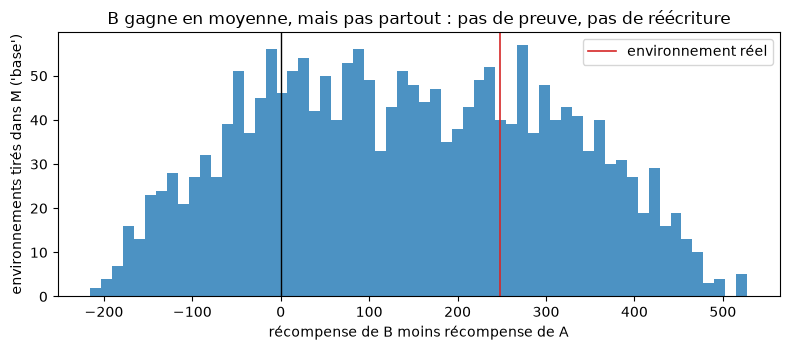

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(d, bins=60, color="tab:blue", alpha=0.8)
ax.axvline(0, color="black", lw=1)
ax.axvline(reel_B - reel_A, color="tab:red", lw=1.2, label="environnement réel")
ax.set_xlabel("récompense de B moins récompense de A")
ax.set_ylabel("environnements tirés dans M ('base')")
ax.set_title("B gagne en moyenne, mais pas partout : pas de preuve, pas de réécriture")
ax.legend(); plt.tight_layout(); plt.show()

### Lecture du résultat

L'histogramme montre où se trouve la masse : B gagne largement dans la plupart des environnements, et l'environnement réel (trait rouge) en fait partie. La queue à gauche du zéro, environ un quart des tirages, suffit pourtant à interdire la preuve. Une machine de Gödel n'agit pas sur une moyenne. Pour qu'elle agisse sur une espérance, il faudrait l'écrire dans la fonction d'utilité avec une loi $\mu$ explicite, et cette loi deviendrait alors un axiome à justifier (section 2.1).

## 6. Le temps de preuve se paie en vie

Jusqu'ici, chaque tentative coûtait 5 pas, quel que soit le travail de preuve. On relie maintenant les deux. La machine reçoit un **budget** `rlimit` par tentative, et un axiome du matériel fixe la durée d'une tentative à $1 + \lfloor budget / 200 \rfloor$ pas.

- Un budget trop petit est bon marché, mais Z3 rend `unknown` et la machine reste sur sa politique initiale.
- Un budget suffisant prouve la réécriture.
- Un budget trop grand prouve aussi, mais chaque tentative dure si longtemps que la bascule arrive tard.

La machine de Gödel ne choisit pas ce budget : il fait partie de son code initial. Le papier ne la limite pas sur ce point, puisqu'elle pourrait réécrire son propre chercheur, budget compris, si elle prouvait que c'est utile (section 6.1, cas 5). Le balayage ci-dessous montre ce qu'une telle réécriture aurait à gagner.

budget  pas/tentative  adopte  a t=   recompense reelle  tentatives
   100              1  calibrage    2              222.0  A:INCONNU B:INCONNU
   200              2  calibrage    4              219.0  A:INCONNU B:INCONNU
   300              2  A            2              297.0  A:PROUVE
   400              3  A            3              295.5  A:PROUVE
   600              4  A            4              294.0  A:PROUVE
  1000              6  B           12              534.0  A:REFUTE B:PROUVE
  2000             11  B           22              504.0  A:REFUTE B:PROUVE
  4000             21  B           42              444.0  A:REFUTE B:PROUVE
  8000             41  B           82              324.0  A:REFUTE B:PROUVE
 16000             81  B          162               84.0  A:REFUTE B:PROUVE
 32000            161  A          161               58.5  A:PROUVE


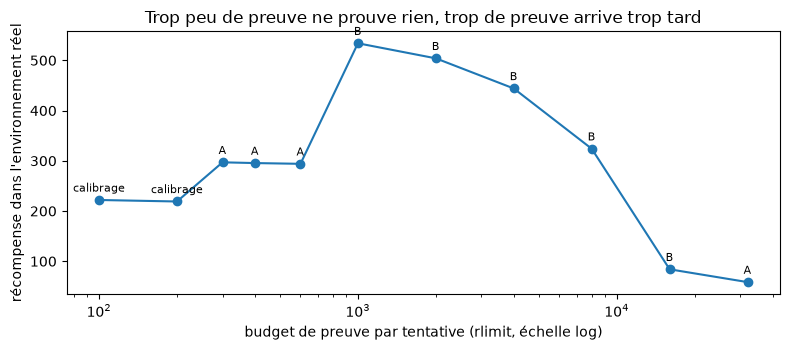

In [8]:
T = 200
budgets = [100, 200, 300, 400, 600, 1000, 2000, 4000, 8000, 16000, 32000]
resultats = []
for b in budgets:
    c = 1 + b // 200
    plan, journal = machine(["A", "B"], "savoir", T, c, budget=b)
    verdicts = " ".join(f"{e['candidat']}:{e['verdict']}" for e in journal)
    resultats.append((b, c, politique_finale(plan), plan[-1][0], gain_reel(plan, T, VRAI), verdicts))

print("budget  pas/tentative  adopte  a t=   recompense reelle  tentatives")
for b, c, pol, tb, g, v in resultats:
    print(f"{b:6d}  {c:13d}  {pol:9s} {tb:4d}  {g:17.1f}  {v}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.semilogx([r[0] for r in resultats], [r[4] for r in resultats], "o-")
for b, c, pol, tb, g, v in resultats:
    ax.annotate(pol, (b, g), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set_xlabel("budget de preuve par tentative (rlimit, échelle log)")
ax.set_ylabel("récompense dans l'environnement réel")
ax.set_title("Trop peu de preuve ne prouve rien, trop de preuve arrive trop tard")
plt.tight_layout(); plt.show()

### Lecture du résultat

La récompense réelle dessine un U inversé en fonction du budget de preuve :

- **budget 100 à 200 : rien n'est prouvé.** Z3 rend `unknown` pour les deux candidats, la machine reste sur sa politique initiale et obtient 222 puis 219 ;
- **budget 300 à 600 : A est prouvé, pas B.** La machine sait que son budget futur ne suffira pas pour B, qui demande environ 940 de `rlimit`. Son « continuer » vaut donc le calibrage, et A le bat. Elle obtient environ 295 ;
- **budget 1 000 : le meilleur point.** B est prouvé en 6 pas par tentative et adopté à $t = 12$, pour 534 ;
- **au-delà, chaque tentative coûte plus de vie qu'elle n'en rapporte.** La bascule recule à $t = 22, 42, 82, 162$, et la récompense tombe à 84 ;
- **budget 32 000 : une seule tentative tient dans la vie.** A est prouvé à $t = 161$, et il ne reste presque rien à récolter (58,5).

Le meilleur budget est le plus petit qui suffit à prouver la meilleure réécriture. Ce budget dépend de la difficulté de la preuve, que la machine ne connaît pas d'avance. C'est l'argument de la section 5 pour BIOPS, qui ne fixe pas de budget mais partage le temps entre les techniques de preuve.

## 7. Carte des décisions : coût de preuve et durée de vie

Pour finir, on balaie le coût d'une tentative (1 à 40 pas) et la durée de vie (15 à 200 pas), toujours avec le jeu `savoir`. La carte montre quelle politique la machine adopte dans chaque case : la politique initiale (elle n'a rien prouvé à temps), A ou B.

1520 cases : {'calibrage': 81, 'A': 311, 'B': 1128}
cout  1 pas : A adopte des T=15, B adopte des T=25
cout  5 pas : A adopte des T=15, B adopte des T=35
cout 20 pas : A adopte des T=25, B adopte des T=65
cout 40 pas : A adopte des T=45, B adopte des T=105


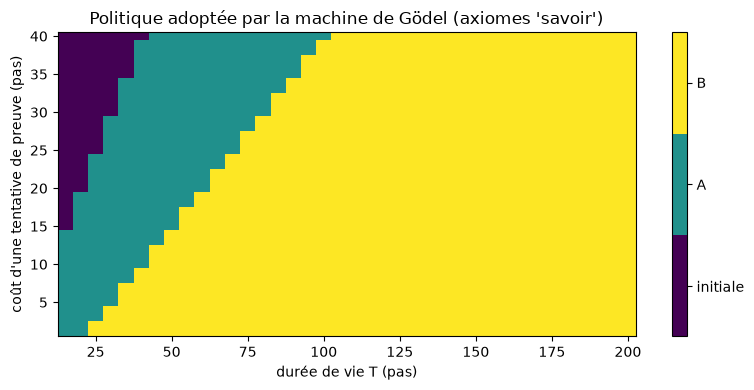

In [9]:
couts = list(range(1, 41, 1))
vies = list(range(15, 201, 5))
code_pol = {"calibrage": 0, "A": 1, "B": 2}
carte = np.zeros((len(couts), len(vies)))
for i, c in enumerate(couts):
    for j, T in enumerate(vies):
        plan, _ = machine(["A", "B"], "savoir", T, c)
        carte[i, j] = code_pol[politique_finale(plan)]

effectifs = {nom: int((carte == v).sum()) for nom, v in code_pol.items()}
print(f"{carte.size} cases : {effectifs}")
for c in (1, 5, 20, 40):
    i = couts.index(c)
    seuil_B = next((vies[j] for j in range(len(vies)) if carte[i, j] == 2), None)
    seuil_A = next((vies[j] for j in range(len(vies)) if carte[i, j] == 1), None)
    print(f"cout {c:2d} pas : A adopte des T={seuil_A}, B adopte des T={seuil_B}")

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(carte, origin="lower", aspect="auto", cmap=plt.get_cmap("viridis", 3),
               extent=[vies[0] - 2.5, vies[-1] + 2.5, couts[0] - 0.5, couts[-1] + 0.5])
cb = fig.colorbar(im, ticks=[0.33, 1, 1.67]); cb.ax.set_yticklabels(["initiale", "A", "B"])
ax.set_xlabel("durée de vie T (pas)")
ax.set_ylabel("coût d'une tentative de preuve (pas)")
ax.set_title("Politique adoptée par la machine de Gödel (axiomes 'savoir')")
plt.tight_layout(); plt.show()

### Lecture du résultat

La carte a trois régions séparées par des frontières presque linéaires :

- **en haut à gauche, la politique initiale** (81 cases) : les preuves coûtent trop cher pour la vie restante, et la machine ne finit aucune tentative utile ;
- **une bande centrale, le levier A** (311 cases) : la vie suffit à prouver A mais pas à rentabiliser l'échauffement de B après deux tentatives ;
- **à droite, le levier B** (1 128 cases) : la vie est assez longue.

La frontière A/B se déplace vers les longues vies quand le coût d'une tentative augmente : B est adopté dès $T = 25$ pour un pas par tentative, mais seulement à partir de $T = 105$ pour 40 pas. Le coût de la preuve n'est pas un détail d'implémentation. Il fait partie de l'utilité, comme l'exige l'éq. (1), qui compte toute la vie de la machine, recherche de preuves comprise.

## 8. Exercices

### Exercice 1 — Un candidat mixte

Ajoutez à `POLITIQUES` un candidat `"AB"` qui presse A pendant 20 pas puis passe à B (l'échauffement de B commence au pas 21). Placez-le en troisième position, puis en première. Avant d'exécuter, prédisez ce que fait la machine de Gödel sur $T = 200$ avec le jeu `savoir`. Vérifiez ensuite, et expliquez pourquoi l'ordre d'énumération des candidats change ou non la politique adoptée.

In [10]:
# Exercice 1 : candidat mixte "AB"
# TODO etudiant : ajouter POLITIQUES["AB"] = lambda D, E: ...  (attention au cas D < 20)
# Indice : r * min(D, 20) + q * positif(D - 20 - w), en gardant positif() pour la partie symbolique
# Etape 2 : machine(["A", "B", "AB"], "savoir", 200, 5) puis machine(["AB", "A", "B"], ...)
print("Exercice a completer")

Exercice a completer


### Exercice 2 — Le théorème cible relâché

La section 4.2 remplace le $>$ de l'éq. (2) par un $\geq$ : la machine se réécrit dès qu'elle prouve que la réécriture **n'empire pas** les choses. Ajoutez un paramètre `relache` à `machine` qui utilise `>=` dans `cible`. Trouvez une durée de vie $T$ où les deux versions adoptent des politiques différentes avec le jeu `savoir`, et dites laquelle obtient la meilleure récompense réelle.

In [11]:
# Exercice 2 : theoreme cible relache (section 4.2)
# TODO etudiant : copier machine() en machine_relachee() avec u_switch >= u_keep
# Indice : comparer machine() et machine_relachee() sur le meme couple (T, jeu "savoir") et relever les T ou les deux politiques different
resultat = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


### Exercice 3 — Combien vaut un axiome ?

La section 5 a trouvé l'écart minimal $e$ qui rend B prouvable. Calculez, pour chaque valeur de $e$ entre 0 et 2 (pas de 0,1), la récompense réelle de la machine de Gödel dans l'environnement `VRAI`, avec le jeu `base` et l'axiome `ecart=e`. Tracez cette courbe. Elle mesure ce que vaut, en récompense, une connaissance supplémentaire sur l'environnement. Que se passe-t-il si l'axiome ajouté est **faux** pour l'environnement réel, par exemple $e = 2$ alors que $q - r = 1{,}5$ ?

In [12]:
# Exercice 3 : valeur d'un axiome sur l'environnement
# TODO etudiant : pour e in np.arange(0, 2.01, 0.1) : plan, _ = machine(["A", "B"], "base", 200, 5, ecart=e)
# Etape 2 : gain_reel(plan, 200, VRAI), puis tracer la courbe
# Indice : pour chaque e, comparer la recompense reelle (sur VRAI) a la recompense attendue sous l'axiome ecart=e
valeurs = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


## Limites du jouet

- **L'arithmétique est décidable.** Les théorèmes cibles portent sur l'arithmétique linéaire réelle, avec trois paramètres. Z3 les tranche toujours, à budget suffisant. La machine du papier vit dans des théories où l'incomplétude de Gödel s'applique : certaines réécritures utiles y sont vraies sans être prouvables, quel que soit le budget. Ici, seul le manque d'axiomes ou de temps empêche une preuve.
- **Le modèle de soi est calculé hors coût.** Pour obtenir $u_{keep}$, la machine simule sa recherche future en appelant Z3, et ces appels ne sont pas facturés en pas de vie. Dans le papier, cette prédiction est elle-même un théorème à prouver, dont la preuve consomme du temps.
- **La dominance est point par point.** Prouver l'inégalité pour **tout** environnement de $\mathcal{M}$ est plus fort que ce qu'exige l'éq. (1), qui ne demande que l'inégalité des espérances sous $\mu$. Le jouet échange cette généralité contre des preuves en arithmétique linéaire.
- **Les candidats sont donnés.** Le papier énumère des programmes de preuve par recherche universelle. Ici, la liste des réécritures est fixée d'avance et ne contient que trois politiques.

## Conclusion

La machine de Gödel ramène l'auto-amélioration à une règle unique : se réécrire seulement quand on a prouvé que se réécrire vaut mieux que continuer. Ce notebook l'a fait tourner avec Z3 comme chercheur de preuves. Il en ressort trois résultats :

1. comparer à « continuer » plutôt qu'au statu quo fait refuser une amélioration réelle (A) pour en attendre une meilleure (B), et rapporte 540 au lieu de 292,5. L'optimalité reste relative à la machine elle-même : une machine plus risquée peut faire mieux dans certains environnements ;
2. la prudence a un prix mesurable : 247,5 abandonnés dans l'environnement réel quand B n'est pas prouvable. Un axiome modeste, $q \geq r + 0{,}5$, suffit à récupérer ce gain ;
3. le temps de preuve se paie dans la même monnaie que la récompense : un budget trop petit ne prouve rien, un budget trop grand arrive trop tard.

**Pour aller plus loin** : [Z3-05 Quantificateurs et preuves](Z3-05-Quantifiers-Proofs-Python.ipynb) pour la mécanique des preuves par réfutation, et la section 6 du papier pour les objections classiques, comme le chercheur de preuves qui s'efface lui-même.